<h1 style="color:white;text-align:center;font-family:'Georgia';background-color:#003366;padding:20px;border-radius:12px;">
  🎯 PROJET DATA MINING : Segmentation de la clientèle
</h1>

<p style="color:white;text-align:center;font-family:'Georgia';background-color:#003366;padding:20px;border-radius:12px;">
  RÉALISÉ PAR
</p>

* **KONE Abdoulaye**
* **N’GUESSAN Kouamé Kan Armand Loïc**
* **SAWADOGO Wend-yam Albert**
* **CHEFOUET CHETSONG Ghislain Joël**

<p style="color:white;text-align:center;font-family:'Georgia';background-color:#003366;padding:20px;border-radius:12px;">
  SUPERVISÉ PAR
</p>

* **M. LALY** — ENSEA Abidjan, cours de Data Mining (AS3, juillet 2025)


<img src="images/segmentation1.jpg">

Pour aborder ce projet, nous appliquons une technique de **clustering non supervisé** sur les données d’une enseigne de la grande distribution (jeu de données public *Customer Personality Analysis*).

🔍 **Objectifs :**
- Identifier des groupes de clients distincts.
- Adapter les produits et services aux besoins spécifiques de chaque segment.
- Améliorer la prise de décision fondée sur les données.

---

<a id='top'></a>
<p style="background-color:#003366;font-family:Georgia;color:#FFF9ED;font-size:150%;padding:20px;text-align:center;border-radius:10px 10px;">TABLE DES MATIÈRES</p>

* [1. Importation des bibliothèques](#1)
* [2. Chargement des données](#2)
* [3. Nettoyage et création de variables](#3)
* [4. Prétraitement des données](#4)
* [5. Réduction de dimension (ACP)](#5)
* [6. Clustering](#6)
* [7. Évaluation de la segmentation](#7)
* [8. Profilage des clusters](#8)
* [9. Conclusion](#9)
* [10. Sources](#10)


<a id="1"></a>
# <p style="background-color:#003366;font-family:Georgia;color:#FFF9ED;font-size:150%;text-align:center;border-radius:10px 10px;">📦 IMPORTATION DES BIBLIOTHÈQUES</p>


In [7]:
import os
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch
import seaborn as sns
import missingno as msno

# Prétraitement
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.decomposition import PCA

# Clustering et évaluation
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score, davies_bouldin_score

warnings.simplefilter("ignore")

# Graine fixée pour la reproductibilité
np.random.seed(42)

# Dossier des figures reprises dans le README
IMG_DIR = "images"
os.makedirs(IMG_DIR, exist_ok=True)


def sauvegarder(nom_fichier):
    """Enregistre la figure courante dans le dossier images/."""
    plt.savefig(os.path.join(IMG_DIR, nom_fichier), dpi=100, bbox_inches="tight")


***

<a id="2"></a>
# <p style="background-color:#003366;font-family:Georgia;color:#FFF9ED;font-size:150%;text-align:center;border-radius:10px 10px;">📂 CHARGEMENT DES DONNÉES</p>


In [8]:
# Chargement des données (fichier séparé par des tabulations)
data = pd.read_csv("data/marketing_campaign.csv", sep="\t")
print("Nombre de lignes :", len(data))
data.head()

Nombre de lignes : 2240


,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,...,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Z_CostContact,Z_Revenue,Response
0,5524,1957,Graduation,Single,58138.0,0,0,04-09-2012,58,635,...,7,0,0,0,0,0,0,3,11,1
1,2174,1954,Graduation,Single,46344.0,1,1,08-03-2014,38,11,...,5,0,0,0,0,0,0,3,11,0
2,4141,1965,Graduation,Together,71613.0,0,0,21-08-2013,26,426,...,4,0,0,0,0,0,0,3,11,0
3,6182,1984,Graduation,Together,26646.0,1,0,10-02-2014,26,11,...,6,0,0,0,0,0,0,3,11,0
4,5324,1981,PhD,Married,58293.0,1,0,19-01-2014,94,173,...,5,0,0,0,0,0,0,3,11,0


In [9]:
# Taille des données
data.shape

(2240, 29)

***

<a id="3"></a>
# <p style="background-color:#003366;font-family:Georgia;color:#FFF9ED;font-size:150%;text-align:center;border-radius:10px 10px;">🧹 NETTOYAGE ET CRÉATION DE VARIABLES</p>

**🔍 Dans cette section, nous allons réaliser :**
* le nettoyage des données ;
* la création et la transformation de variables (*feature engineering*).

---
Afin de déterminer précisément les étapes de nettoyage nécessaires, commençons par explorer la structure des données.


In [10]:
# Informations sur les variables
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 2240 entries, 0 to 2239
Data columns (total 29 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   ID                   2240 non-null   int64  
 1   Year_Birth           2240 non-null   int64  
 2   Education            2240 non-null   str    
 3   Marital_Status       2240 non-null   str    
 4   Income               2216 non-null   float64
 5   Kidhome              2240 non-null   int64  
 6   Teenhome             2240 non-null   int64  
 7   Dt_Customer          2240 non-null   str    
 8   Recency              2240 non-null   int64  
 9   MntWines             2240 non-null   int64  
 10  MntFruits            2240 non-null   int64  
 11  MntMeatProducts      2240 non-null   int64  
 12  MntFishProducts      2240 non-null   int64  
 13  MntSweetProducts     2240 non-null   int64  
 14  MntGoldProds         2240 non-null   int64  
 15  NumDealsPurchases    2240 non-null   int64  
 16 

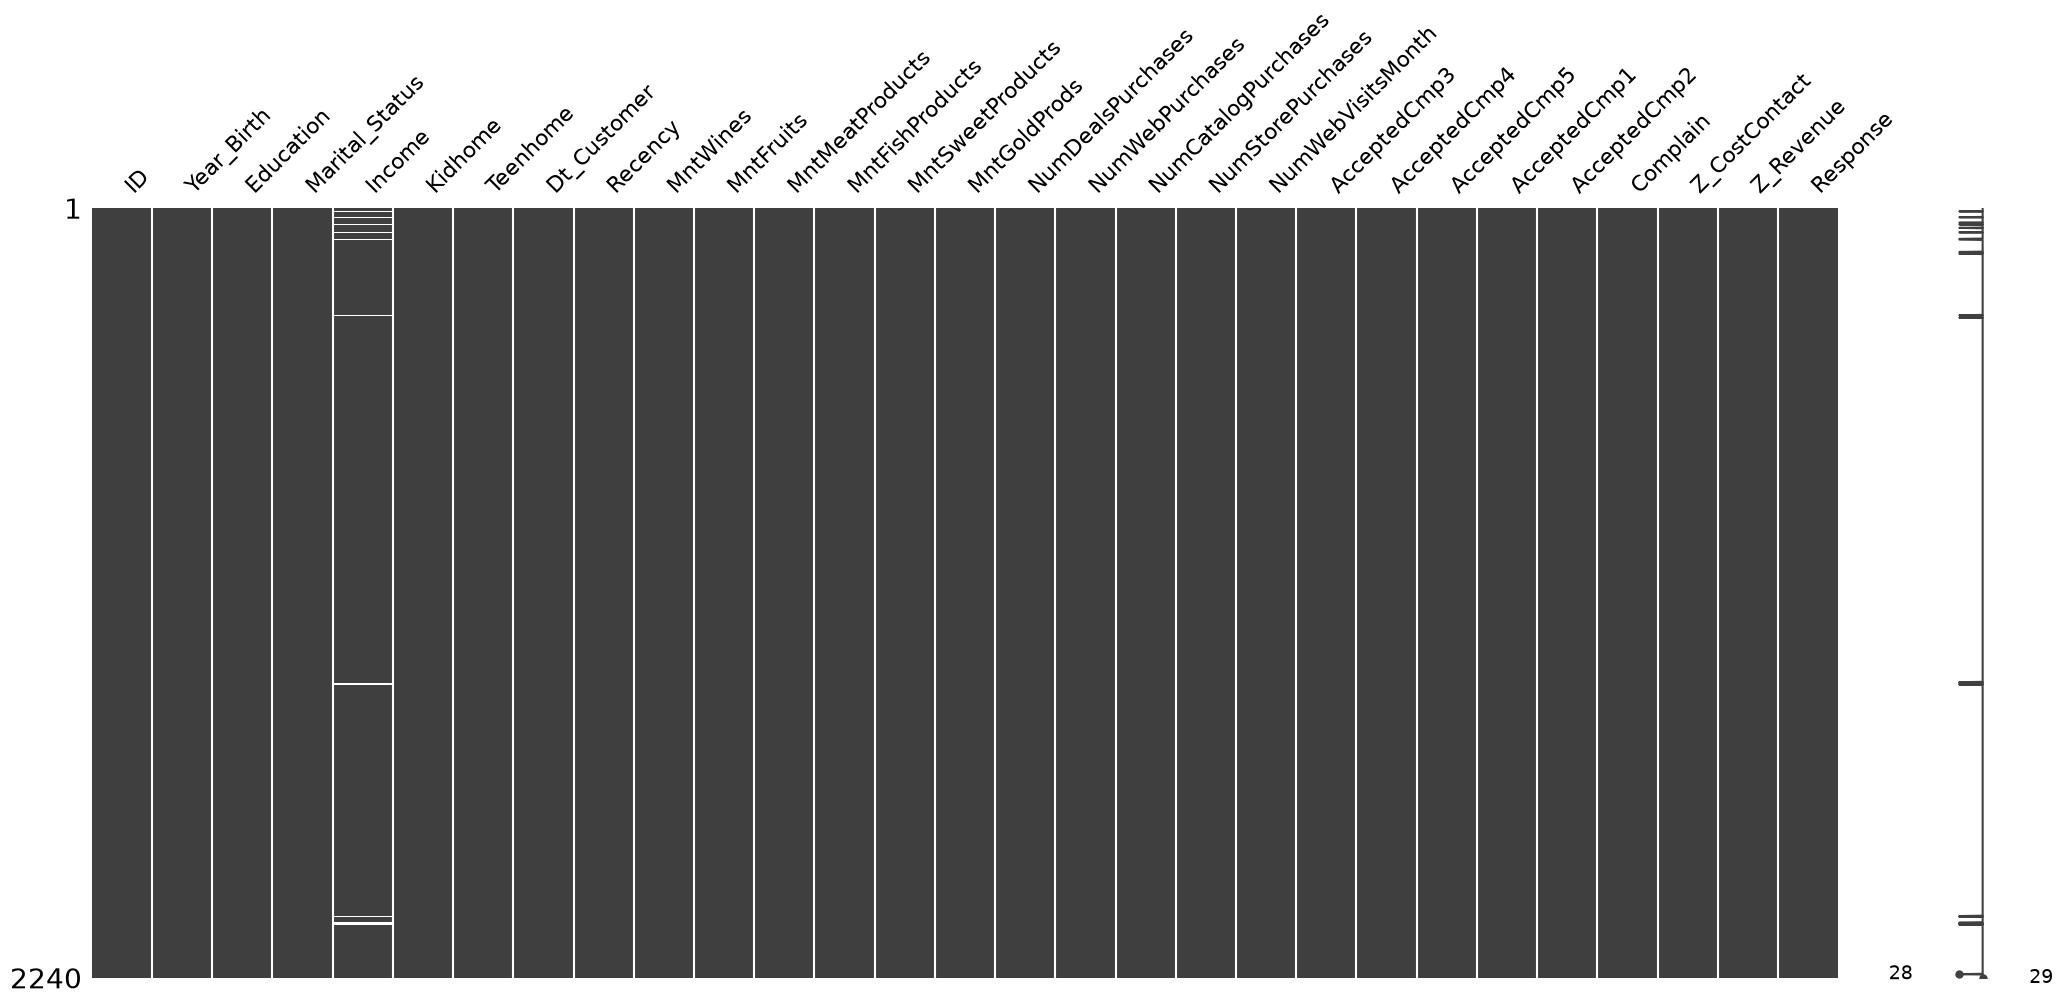

In [11]:
# Affichage des valeurs manquantes sous forme de graphique
msno.matrix(data)
plt.show()


**📌 À partir des informations sur les variables, nous pouvons tirer les conclusions suivantes**

* La variable `Income` contient des valeurs manquantes.
* La variable `Dt_Customer`, qui représente la date d’enregistrement du client dans la base de données, n’a pas encore été convertie au format `DateTime`.
* Certaines variables du jeu de données sont de type catégoriel (`object`). Il faudra donc les encoder en variables numériques par la suite.

🔧 Dans un premier temps, nous allons supprimer les lignes contenant des valeurs manquantes dans la variable `Income`.


In [12]:
# Suppression des lignes sans revenu renseigné
data = data.dropna()
print("Nombre de lignes après suppression des valeurs manquantes :", len(data))

Nombre de lignes après suppression des valeurs manquantes : 2216


**🛠️ Création d'une nouvelle variable à partir de `Dt_Customer`**

Nous allons maintenant créer une variable dérivée de **`Dt_Customer`** afin d’estimer le **nombre de jours depuis l'enregistrement de chaque client** dans la base de données de l’entreprise.

👉 Pour simplifier l’analyse, cette durée sera calculée **par rapport à la date d’enregistrement la plus récente** observée dans les données.

Avant de procéder, examinons les dates les plus anciennes et les plus récentes présentes dans la colonne `Dt_Customer`.


In [13]:
# Conversion en datetime (format jour-mois-année)
data["Dt_Customer"] = pd.to_datetime(data["Dt_Customer"], dayfirst=True)

print("📅 Date d'enregistrement la plus récente :", data["Dt_Customer"].max().date())
print("📅 Date d'enregistrement la plus ancienne :", data["Dt_Customer"].min().date())

📅 Date d'enregistrement la plus récente : 2014-06-29
📅 Date d'enregistrement la plus ancienne : 2012-07-30


In [14]:
# Création de la variable "Customer_For" : ancienneté du client en jours,
# mesurée par rapport à la date d'enregistrement la plus récente
data["Customer_For"] = (data["Dt_Customer"].max() - data["Dt_Customer"]).dt.days

**🔍 Exploration des variables catégorielles**

Nous allons maintenant examiner les **valeurs uniques** des variables catégorielles afin d’obtenir une vision plus claire de leur contenu et de mieux comprendre la structure des données.


In [15]:
print("📊 Répartition des catégories dans la variable 'Marital_Status' :\n")
print(data["Marital_Status"].value_counts(), "\n")

print("🎓 Répartition des catégories dans la variable 'Education' :\n")
print(data["Education"].value_counts())


📊 Répartition des catégories dans la variable 'Marital_Status' :

Marital_Status
Married     857
Together    573
Single      471
Divorced    232
Widow        76
Alone         3
Absurd        2
YOLO          2
Name: count, dtype: int64 

🎓 Répartition des catégories dans la variable 'Education' :

Education
Graduation    1116
PhD            481
Master         365
2n Cycle       200
Basic           54
Name: count, dtype: int64


Pour faciliter le profilage, nous allons maintenant :

- calculer l’**âge** du client à partir de **`Year_Birth`**. Les données couvrent la période 2012-2014 : l’âge est donc calculé **en 2014**, année de la dernière inscription observée ;
- créer une variable **`Spent`** représentant le **montant total dépensé** par le client dans les six catégories de produits sur deux ans ;
- créer une variable **`Living_With`** à partir de **`Marital_Status`** pour refléter la **situation de cohabitation** (en couple ou seul) ;
- créer une variable **`Children`** donnant le **nombre total d’enfants dans le foyer** (enfants et adolescents) ;
- créer une variable **`Family_Size`** représentant la **taille du foyer** ;
- créer une variable **`Is_Parent`** indiquant si le client est **parent ou non** ;
- regrouper les modalités de **`Education`** en **trois catégories** ;
- supprimer les variables devenues **redondantes ou inutiles**.


In [16]:
# 🛠️ Ingénierie des variables

# Âge du client en 2014, fin de la période d'observation
ANNEE_REFERENCE = 2014
data["Age"] = ANNEE_REFERENCE - data["Year_Birth"]

# Dépense totale du client sur toutes les catégories de produits
data["Spent"] = (
    data["MntWines"]
    + data["MntFruits"]
    + data["MntMeatProducts"]
    + data["MntFishProducts"]
    + data["MntSweetProducts"]
    + data["MntGoldProds"]
)

# Situation de cohabitation dérivée du statut matrimonial
data["Living_With"] = data["Marital_Status"].replace({
    "Married": "Partner",
    "Together": "Partner",
    "Absurd": "Alone",
    "Widow": "Alone",
    "YOLO": "Alone",
    "Divorced": "Alone",
    "Single": "Alone",
})

# Nombre total d'enfants dans le foyer (enfants + adolescents)
data["Children"] = data["Kidhome"] + data["Teenhome"]

# Taille du foyer (adultes + enfants)
data["Family_Size"] = data["Living_With"].map({"Alone": 1, "Partner": 2}) + data["Children"]

# Statut parental (1 = parent, 0 = non parent)
data["Is_Parent"] = np.where(data["Children"] > 0, 1, 0)

# Regroupement des niveaux d'éducation en 3 catégories
data["Education"] = data["Education"].replace({
    "Basic": "Undergraduate",
    "2n Cycle": "Undergraduate",
    "Graduation": "Graduate",
    "Master": "Postgraduate",
    "PhD": "Postgraduate",
})

# Renommage des colonnes de dépenses pour plus de clarté
data = data.rename(columns={
    "MntWines": "Wines",
    "MntFruits": "Fruits",
    "MntMeatProducts": "Meat",
    "MntFishProducts": "Fish",
    "MntSweetProducts": "Sweets",
    "MntGoldProds": "Gold",
})

# Suppression des variables devenues redondantes ou inutiles
# (Z_CostContact et Z_Revenue sont constantes)
to_drop = ["Marital_Status", "Dt_Customer", "Z_CostContact", "Z_Revenue", "Year_Birth", "ID"]
data = data.drop(to_drop, axis=1)

Examinons les statistiques descriptives avec les nouvelles variables.

In [17]:
data.describe()

,Income,Kidhome,Teenhome,Recency,Wines,Fruits,Meat,Fish,Sweets,Gold,...,AcceptedCmp1,AcceptedCmp2,Complain,Response,Customer_For,Age,Spent,Children,Family_Size,Is_Parent
count,2216.000000,2216.000000,2216.000000,2216.000000,2216.000000,2216.000000,2216.000000,2216.000000,2216.000000,2216.000000,...,2216.000000,2216.000000,2216.000000,2216.000000,2216.000000,2216.000000,2216.000000,2216.000000,2216.000000,2216.000000
mean,52247.251354,0.441787,0.505415,49.012635,305.091606,26.356047,166.995939,37.637635,27.028881,43.965253,...,0.064079,0.013538,0.009477,0.150271,353.521209,45.179603,607.075361,0.947202,2.592509,0.714350
std,25173.076661,0.536896,0.544181,28.948352,337.327920,39.793917,224.283273,54.752082,41.072046,51.815414,...,0.244950,0.115588,0.096907,0.357417,202.434667,11.985554,602.900476,0.749062,0.905722,0.451825
min,1730.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,18.000000,5.000000,0.000000,1.000000,0.000000
25%,35303.000000,0.000000,0.000000,24.000000,24.000000,2.000000,16.000000,3.000000,1.000000,9.000000,...,0.000000,0.000000,0.000000,0.000000,180.000000,37.000000,69.000000,0.000000,2.000000,0.000000
50%,51381.500000,0.000000,0.000000,49.000000,174.500000,8.000000,68.000000,12.000000,8.000000,24.500000,...,0.000000,0.000000,0.000000,0.000000,355.500000,44.000000,396.500000,1.000000,3.000000,1.000000
75%,68522.000000,1.000000,1.000000,74.000000,505.000000,33.000000,232.250000,50.000000,33.000000,56.000000,...,0.000000,0.000000,0.000000,0.000000,529.000000,55.000000,1048.000000,1.000000,3.000000,1.000000
max,666666.000000,2.000000,2.000000,99.000000,1493.000000,199.000000,1725.000000,259.000000,262.000000,321.000000,...,1.000000,1.000000,1.000000,1.000000,699.000000,121.000000,2525.000000,3.000000,5.000000,1.000000


Les statistiques révèlent des écarts importants entre la moyenne et le maximum pour le **revenu** et l’**âge** :

* un revenu maximal de **666 666**, très éloigné du reste de la distribution ;
* un âge maximal de **121 ans** (client déclaré né en 1893), manifestement une erreur de saisie.

Pour mieux comprendre l’ensemble du jeu de données, traçons quelques variables sélectionnées.


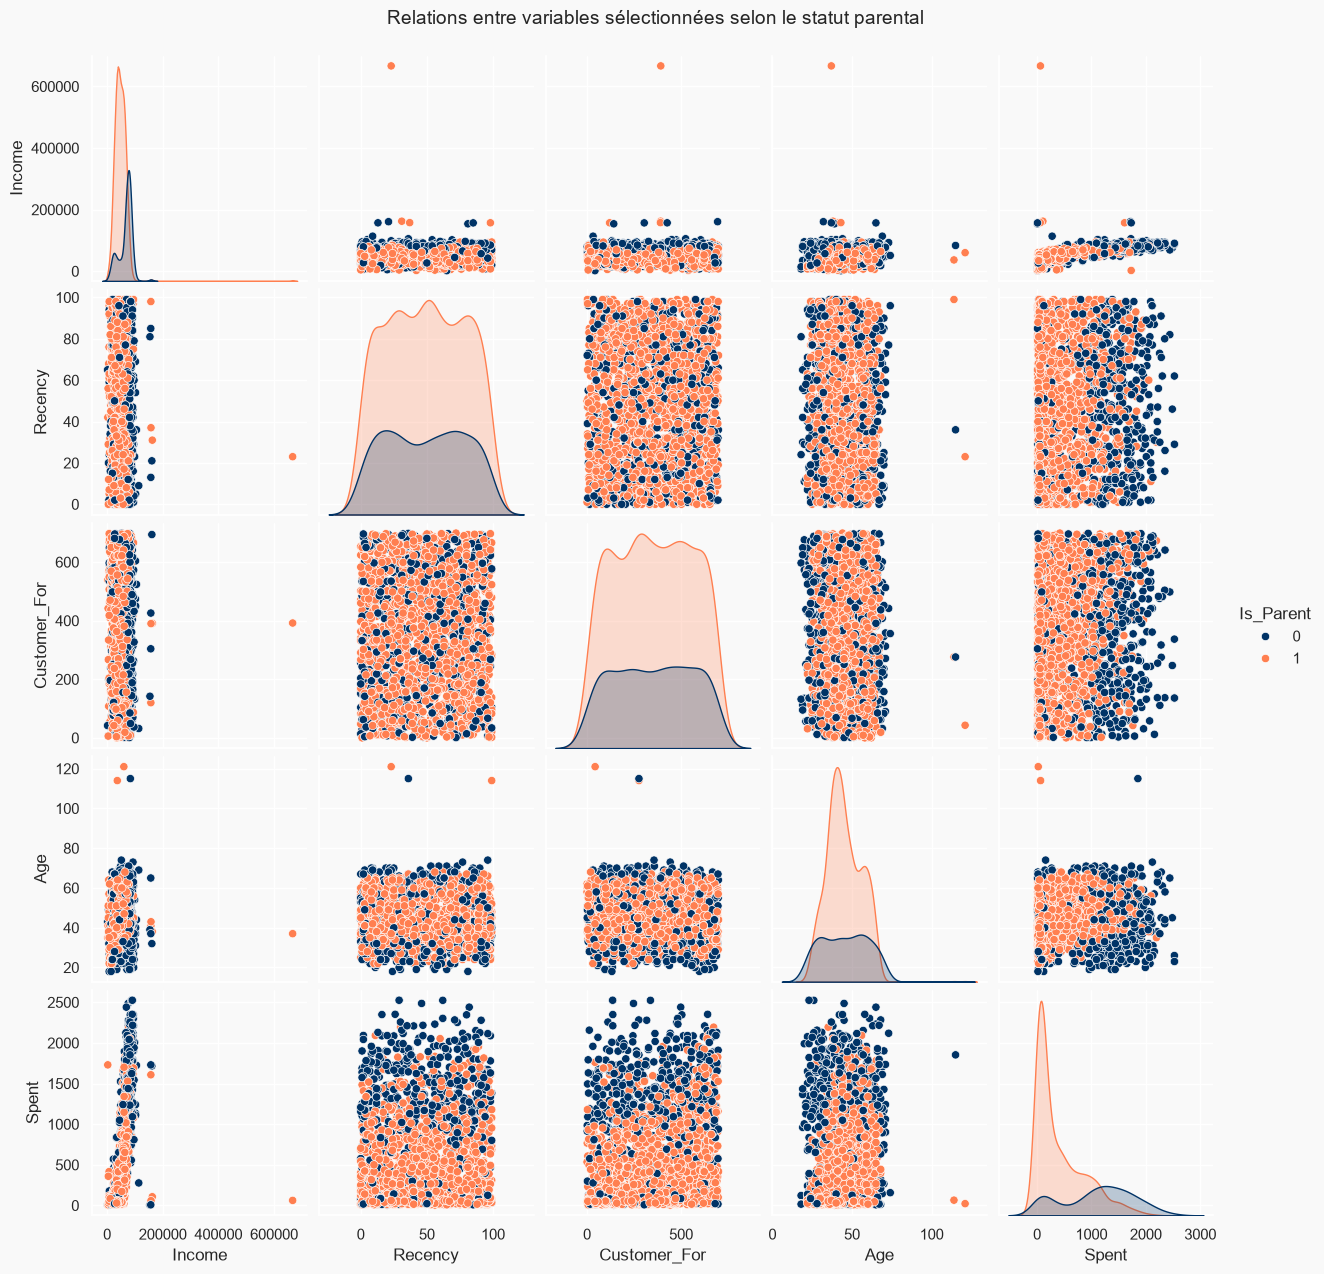

In [18]:
# Style des graphiques
sns.set(rc={"axes.facecolor": "#F9F9F9", "figure.facecolor": "#F9F9F9"})

# Palette commune à tous les graphiques par cluster (clusters 0, 1, 2, 3)
pal = ["#682F2F", "#003366", "#9F8A78", "#F3AB60"]
cmap = ListedColormap(pal)

# Variables à tracer
To_Plot = ["Income", "Recency", "Customer_For", "Age", "Spent", "Is_Parent"]

g = sns.pairplot(data[To_Plot], hue="Is_Parent", palette=["#003366", "#FF7F50"])
g.figure.suptitle("Relations entre variables sélectionnées selon le statut parental", fontsize=14, y=1.02)
plt.show()

Les graphiques confirment la présence de quelques **valeurs aberrantes** sur le **revenu** et l’**âge**.
Pour qu’elles ne faussent pas la suite de l’analyse, nous **supprimons ces observations**.

In [19]:
# Suppression des valeurs aberrantes à l'aide de seuils sur l'âge et le revenu

# Clients de 90 ans ou plus (années de naissance invraisemblables)
data = data[data["Age"] < 90]

# Revenu supérieur à 600 000
data = data[data["Income"] < 600000]

print("Nombre d'observations après suppression des valeurs aberrantes :", len(data))

Nombre d'observations après suppression des valeurs aberrantes : 2212


Examinons ensuite la **corrélation entre les variables numériques**.
Les variables catégorielles sont exclues à ce stade.

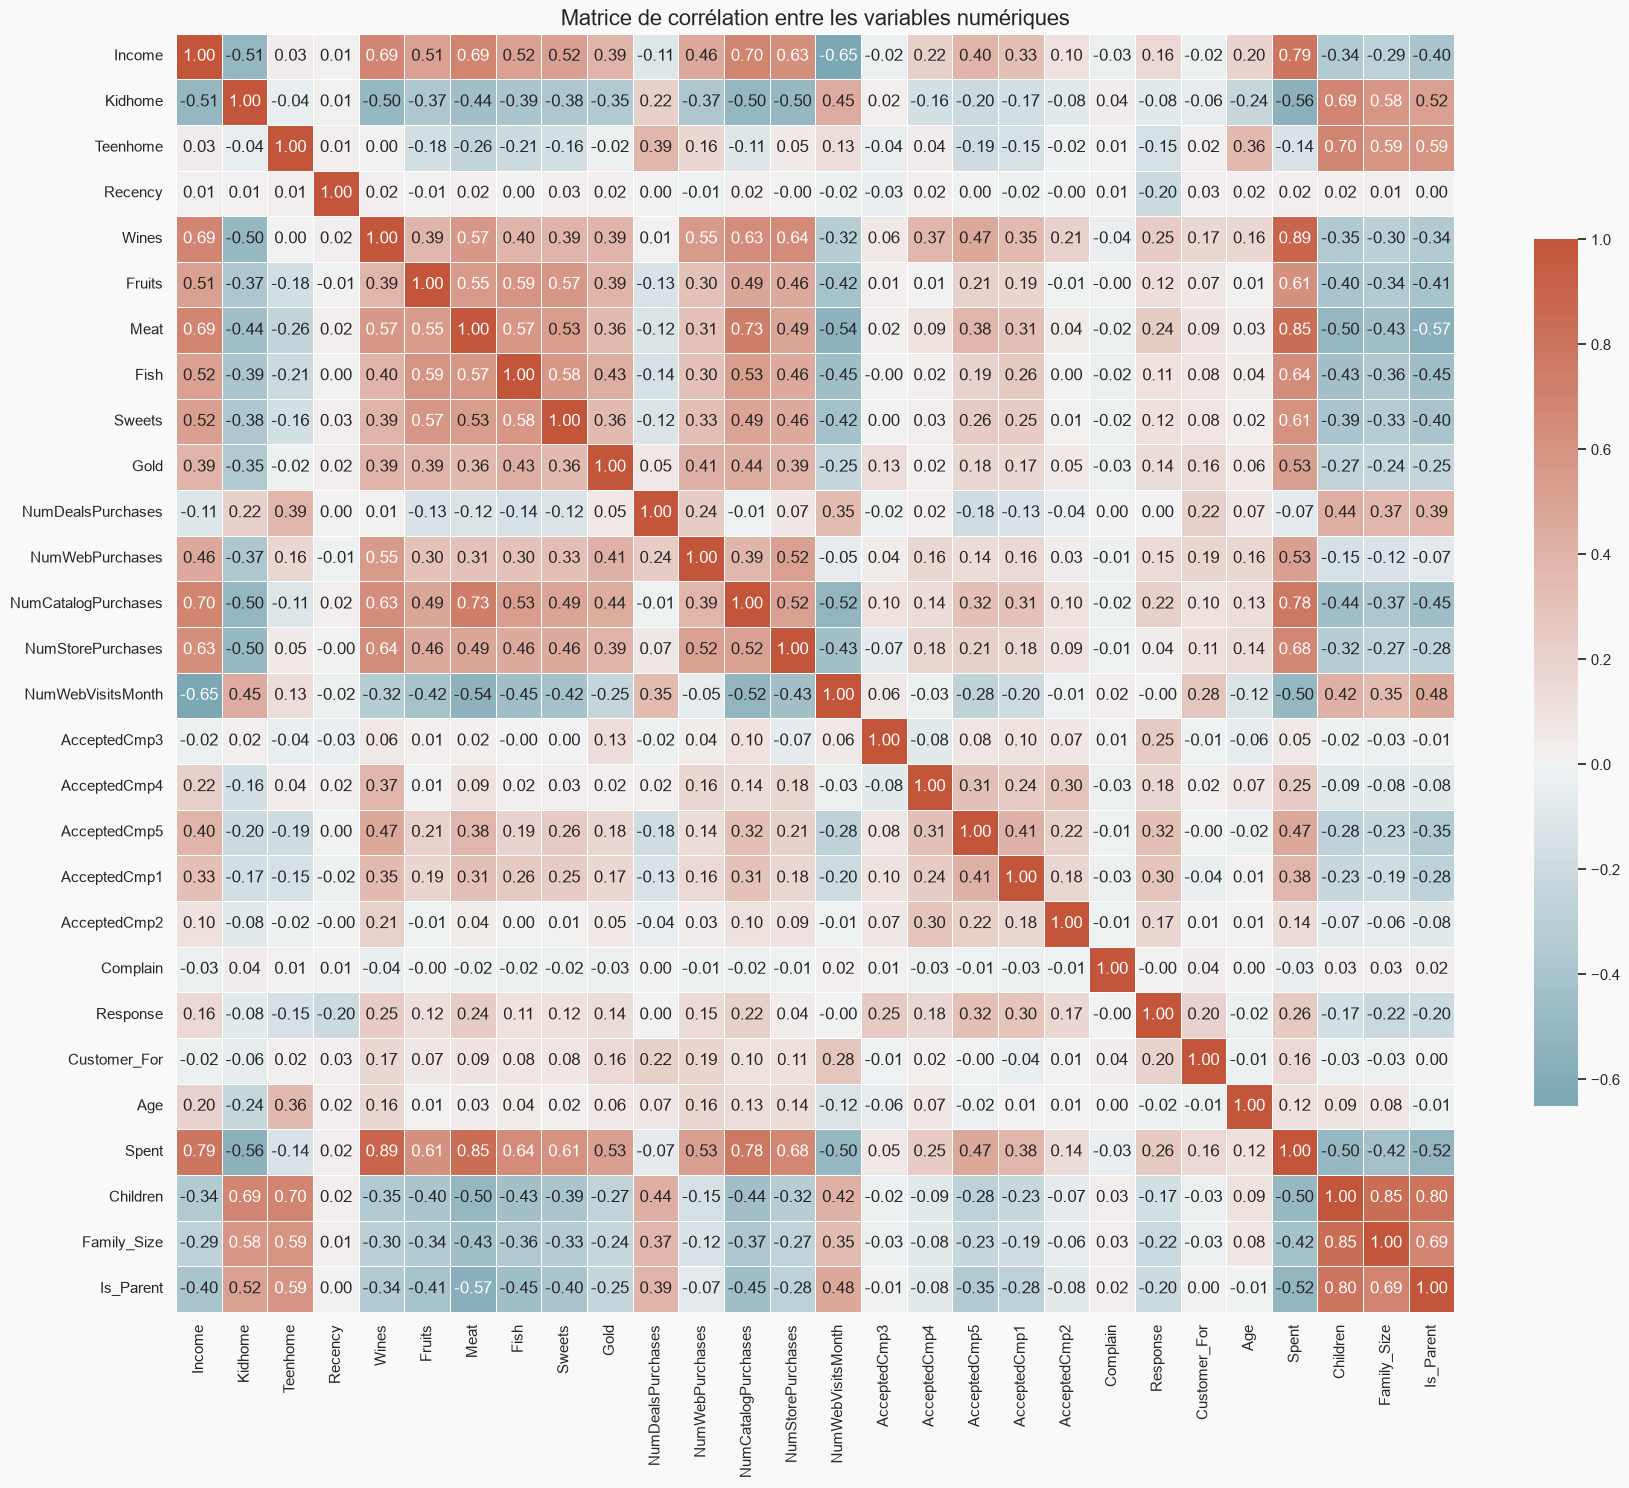

In [20]:
# Matrice de corrélation entre les variables numériques
corrmat = data.corr(numeric_only=True)

plt.figure(figsize=(18, 18))
sns.heatmap(
    corrmat,
    annot=True,
    fmt=".2f",
    cmap=sns.diverging_palette(220, 20, as_cmap=True),
    center=0,
    square=True,
    linewidths=.5,
    cbar_kws={"shrink": .5},
)
plt.title("Matrice de corrélation entre les variables numériques", fontsize=16)
plt.tight_layout()
plt.show()

**🧩 Interprétation de la matrice de corrélation**

* Les variables de **dépenses** (`Wines`, `Meat`, `Fish`, etc.) sont fortement corrélées entre elles et avec **`Spent`**, ce qui est attendu puisque `Spent` en est la somme.
* Le **revenu** (`Income`) est fortement corrélé aux dépenses totales (0,79) et aux achats par catalogue (0,70), et négativement aux **visites du site web** (−0,65) : les clients modestes visitent davantage le site mais achètent moins.
* L’**âge** (`Age`) n’est que faiblement lié aux dépenses (+0,12) ; il est surtout associé à la présence d’adolescents dans le foyer (`Teenhome`, +0,36).
* Le **nombre d’enfants** (`Children`) et le statut de parent (`Is_Parent`) sont **négativement corrélés aux dépenses** (environ −0,5) et positivement aux **achats en promotion** (+0,4), ce qui suggère une contrainte budgétaire.

Ces redondances justifient une réduction de dimension avant le clustering. La section suivante prépare les données en ce sens.

---

<a id="4"></a>
# <p style="background-color:#003366;font-family:Georgia;color:#FFF9ED;font-size:150%;text-align:center;border-radius:10px 10px;">⚙️ PRÉTRAITEMENT DES DONNÉES</p>

**Les étapes suivantes seront appliquées :**

* encodage des variables catégorielles avec **LabelEncoder** ;
* **mise à l’échelle** des variables numériques avec **StandardScaler** ;
* création d’un **sous-ensemble de données** pour la réduction de dimension.

> **Remarque :** `LabelEncoder` attribue les codes par ordre alphabétique (Graduate = 0, Postgraduate = 1, Undergraduate = 2), ce qui ne respecte pas l’ordre naturel des niveaux d’études. Ce choix est conservé ici et discuté dans les limites de l’étude.


In [21]:
# Liste des variables catégorielles
object_cols = [col for col in data.columns if not pd.api.types.is_numeric_dtype(data[col])]

print("Variables catégorielles :", object_cols)

Variables catégorielles : ['Education', 'Living_With']


In [22]:
# Encodage des variables catégorielles avec LabelEncoder
LE = LabelEncoder()
for col in object_cols:
    data[col] = LE.fit_transform(data[col])

print("✅ Toutes les variables sont désormais numériques.")

✅ Toutes les variables sont désormais numériques.


Avant d’appliquer les algorithmes de clustering, nous allons :

* créer une **copie** du jeu de données pour préserver l’original ;
* retirer les variables **liées aux campagnes marketing** et aux réclamations : elles serviront à caractériser les clusters *a posteriori*, pas à les construire ;
* **standardiser** les variables restantes avec `StandardScaler`, afin que chacune pèse de manière comparable.


In [23]:
# Copie du jeu de données
ds = data.copy()

# Retrait des variables liées aux campagnes marketing, plaintes et réponses
cols_del = ["AcceptedCmp3", "AcceptedCmp4", "AcceptedCmp5", "AcceptedCmp1", "AcceptedCmp2", "Complain", "Response"]
ds = ds.drop(cols_del, axis=1)

# Standardisation
scaler = StandardScaler()
scaled_ds = pd.DataFrame(scaler.fit_transform(ds), columns=ds.columns)

print("✅ Toutes les variables ont été mises à l'échelle.")

✅ Toutes les variables ont été mises à l'échelle.


In [24]:
# Données standardisées utilisées pour la réduction de dimension
print("Jeu de données utilisé pour la modélisation :")
scaled_ds.head()

Jeu de données utilisé pour la modélisation :


,Education,Income,Kidhome,Teenhome,Recency,Wines,Fruits,Meat,Fish,Sweets,...,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,Customer_For,Age,Spent,Living_With,Children,Family_Size,Is_Parent
0,-0.893586,0.287105,-0.822754,-0.929699,0.310353,0.977660,1.552041,1.690293,2.453472,1.483713,...,2.503607,-0.555814,0.692181,1.527721,1.018352,1.676245,-1.349603,-1.264598,-1.758359,-1.581139
1,-0.893586,-0.260882,1.040021,0.908097,-0.380813,-0.872618,-0.637461,-0.718230,-0.651004,-0.634019,...,-0.571340,-1.171160,-0.132545,-1.189011,1.274785,-0.963297,-1.349603,1.404572,0.449070,0.632456
2,-0.893586,0.913196,-0.822754,-0.929699,-0.795514,0.357935,0.570540,-0.178542,1.339513,-0.147184,...,-0.229679,1.290224,-0.544908,-0.206048,0.334530,0.280110,0.740959,-1.264598,-0.654644,-1.581139
3,-0.893586,-1.176114,1.040021,-0.929699,-0.795514,-0.872618,-0.561961,-0.655787,-0.504911,-0.585335,...,-0.913000,-0.555814,0.279818,-1.060584,-1.289547,-0.920135,0.740959,0.069987,0.449070,0.632456
4,0.571657,0.294307,1.040021,-0.929699,1.554453,-0.392257,0.419540,-0.218684,0.152508,-0.001133,...,0.111982,0.059532,-0.132545,-0.951915,-1.033114,-0.307562,0.740959,0.069987,0.449070,0.632456


Les données étant prêtes, passons à la **réduction de dimension**, étape clé pour simplifier les données tout en conservant l’essentiel de l’information, ce qui facilite la visualisation et le clustering.

---


<a id="5"></a>
# <p style="background-color:#003366;font-family:Georgia;color:#FFF9ED;font-size:150%;text-align:center;border-radius:10px 10px;">📉 RÉDUCTION DE DIMENSION (ACP)</p>
La matrice de corrélation a montré que de nombreuses variables sont corrélées entre elles, et donc porteuses d’informations redondantes.

Nous appliquons donc une **réduction de dimension** avant le clustering, au moyen de l’**Analyse en Composantes Principales (ACP)**, qui résume les variables en un petit nombre d’axes non corrélés en minimisant la perte d’information.

**Étapes de cette section :**
* choix du nombre de composantes à retenir ;
* réduction de dimension avec l’ACP ;
* visualisation du jeu de données réduit.


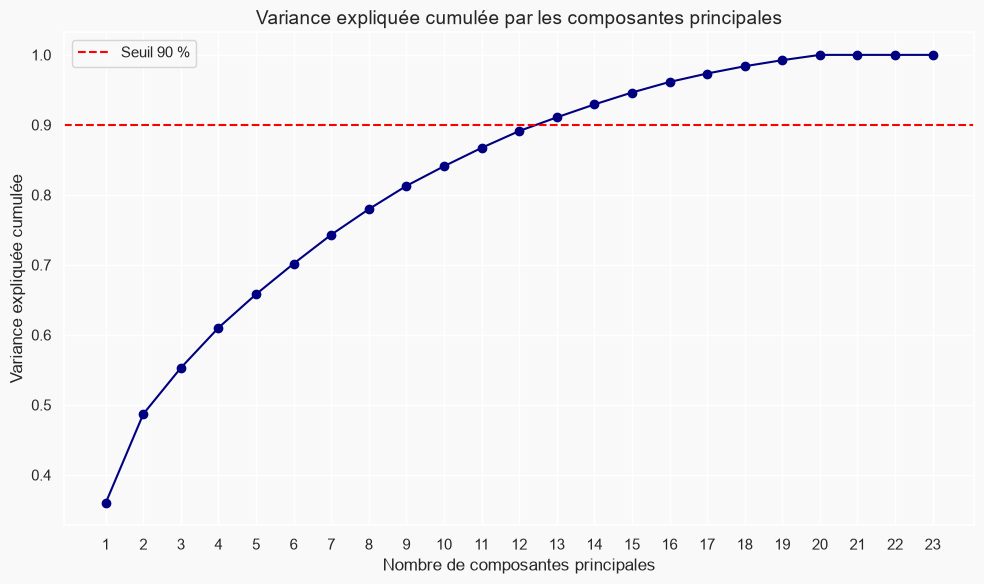

Variance cumulée des 3 premières composantes : 55.30%
Variance cumulée des 4 premières composantes : 61.03%


In [25]:
# ACP sur toutes les composantes possibles
pca_full = PCA()
pca_full.fit(scaled_ds)

# Variance expliquée cumulée
cumulative_variance_full = np.cumsum(pca_full.explained_variance_ratio_)

plt.figure(figsize=(10, 6))
plt.plot(range(1, len(cumulative_variance_full) + 1), cumulative_variance_full, marker="o", linestyle="-", color="navy")
plt.title("Variance expliquée cumulée par les composantes principales", fontsize=14)
plt.xlabel("Nombre de composantes principales", fontsize=12)
plt.ylabel("Variance expliquée cumulée", fontsize=12)
plt.xticks(range(1, len(cumulative_variance_full) + 1))
plt.axhline(y=0.90, color="red", linestyle="--", label="Seuil 90 %")
plt.grid(True)
plt.legend()
plt.tight_layout()
sauvegarder("00_variance_cumulee_acp.png")
plt.show()

print(f"Variance cumulée des 3 premières composantes : {cumulative_variance_full[2]:.2%}")
print(f"Variance cumulée des 4 premières composantes : {cumulative_variance_full[3]:.2%}")

### Choix du nombre de composantes principales

Le graphique présente la variance expliquée cumulée par les composantes principales. Elle augmente rapidement avec les premières composantes, puis la courbe s’aplatit progressivement.

Le seuil de 90 % n’est atteint qu’à la 13ᵉ composante. Nous retenons pourtant les **4 premières composantes principales**, qui expliquent **61 % de la variance totale**. Ce choix privilégie :
- la **simplicité** de la représentation, avec 4 axes au lieu de 23 variables ;
- la **lisibilité** des visualisations et l’interprétation des résultats ;
- un clustering moins sensible au **bruit** porté par les dernières composantes.

L’analyse des clusters et le profilage des clients s’appuient donc sur ces **4 axes principaux**.

> **Remarque :** il n’existe pas de seuil universel de variance expliquée. Le nombre de composantes relève d’un arbitrage entre information conservée et interprétabilité ; ici, l’objectif est une segmentation lisible plutôt qu’une reconstruction fidèle des données.


In [26]:
# ACP réduite à 4 composantes
pca = PCA(n_components=4)
PCA_ds = pd.DataFrame(pca.fit_transform(scaled_ds), columns=["axe1", "axe2", "axe3", "axe4"])
PCA_ds.describe().T

,count,mean,std,min,25%,50%,75%,max
axe1,2212.0,1.284887e-17,2.878602,-5.978124,-2.539470,-0.781595,2.386380,7.452915
axe2,2212.0,5.139550e-17,1.709469,-4.194757,-1.323929,-0.173721,1.234851,6.168189
axe3,2212.0,-6.303979e-17,1.231687,-3.625248,-0.853713,-0.050842,0.863974,6.750458
axe4,2212.0,3.292524e-17,1.147354,-3.127582,-0.758827,-0.012351,0.888047,3.403542


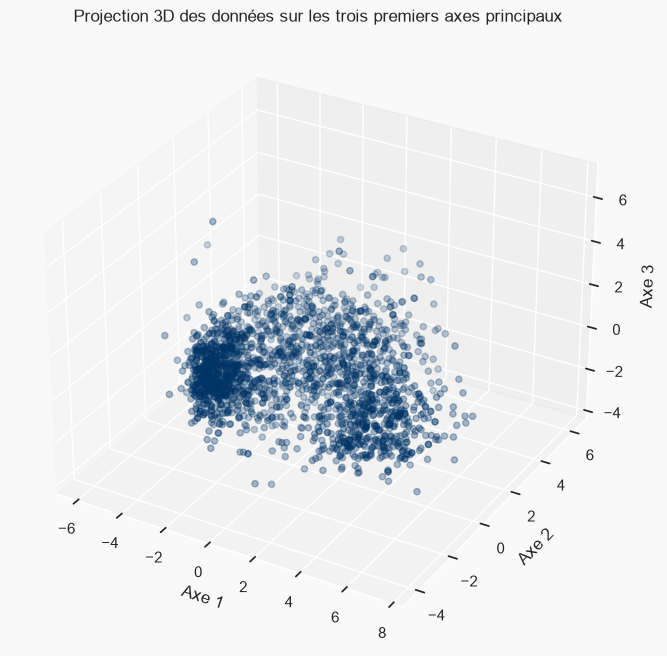

In [27]:
# Projection 3D des données sur les trois premiers axes principaux
x = PCA_ds["axe1"]
y = PCA_ds["axe2"]
z = PCA_ds["axe3"]

fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(111, projection="3d")
ax.scatter(x, y, z, c="#003366", marker="o", alpha=0.6)
ax.set_xlabel("Axe 1")
ax.set_ylabel("Axe 2")
ax.set_zlabel("Axe 3")
ax.set_title("Projection 3D des données sur les trois premiers axes principaux")
plt.show()

***

<a id="6"></a>
# <p style="background-color:#003366;font-family:Georgia;color:#FFF9ED;font-size:150%;text-align:center;border-radius:10px 10px;">📊 CLUSTERING</p>

Les données étant réduites à **quatre dimensions principales**, nous procédons à la segmentation des clients par **clustering agglomératif**. Cette approche hiérarchique ascendante part de chaque individu isolé et fusionne progressivement les groupes les plus proches (critère de Ward) jusqu’à obtenir le nombre de groupes souhaité.

**Étapes du clustering :**
* détermination du nombre de clusters par la méthode du coude ;
* segmentation par clustering agglomératif ;
* visualisation des groupes obtenus.

> La méthode du coude repose ici sur l’inertie de **KMeans**, utilisée comme indicateur rapide de la structure des données. Le choix de k est ensuite contrôlé avec des indices adaptés au clustering agglomératif (section 7).


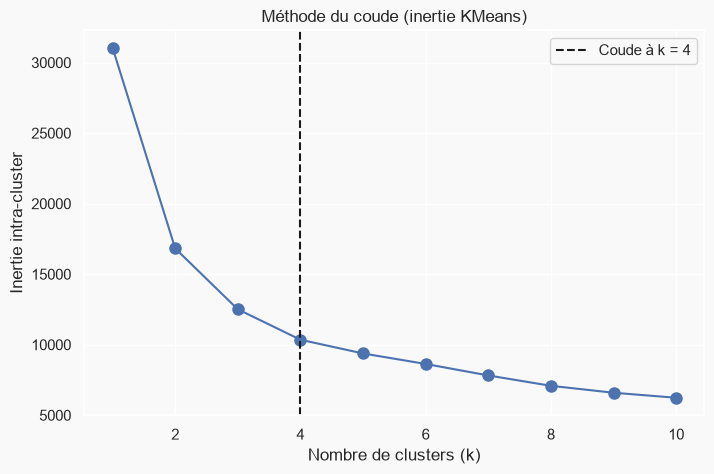

In [28]:
# Méthode du coude : inertie de KMeans pour k = 1 à 10
inertia = []
k_range = range(1, 11)

for k in k_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(PCA_ds)
    inertia.append(kmeans.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(k_range, inertia, "bo-", markersize=8)
plt.axvline(x=4, linestyle="--", color="k", label="Coude à k = 4")
plt.xlabel("Nombre de clusters (k)")
plt.ylabel("Inertie intra-cluster")
plt.title("Méthode du coude (inertie KMeans)")
plt.legend()
plt.grid(True)
sauvegarder("01_methode_du_coude.png")
plt.show()

Le graphique représente l’inertie intra-cluster (somme des carrés des distances aux centres) en fonction du nombre de clusters. L’inertie chute fortement jusqu’à k = 3, puis la décroissance devient nettement plus lente au-delà de **k = 4**.

> Le coude est peu marqué, entre 3 et 4. Nous retenons **k = 4**, qui offre une segmentation plus fine et donc plus exploitable pour le marketing, sans complexifier inutilement l’analyse. Ce choix est contrôlé par les indices de qualité de la section 7.


In [29]:
# Clustering agglomératif en 4 groupes (critère de Ward)
AC = AgglomerativeClustering(n_clusters=4, linkage="ward")
yhat_AC = AC.fit_predict(PCA_ds)
PCA_ds["Clusters"] = yhat_AC

# Ajout des clusters au jeu de données d'origine
data["Clusters"] = yhat_AC

Pour examiner les groupes formés, observons leur répartition dans l’espace des trois premiers axes.

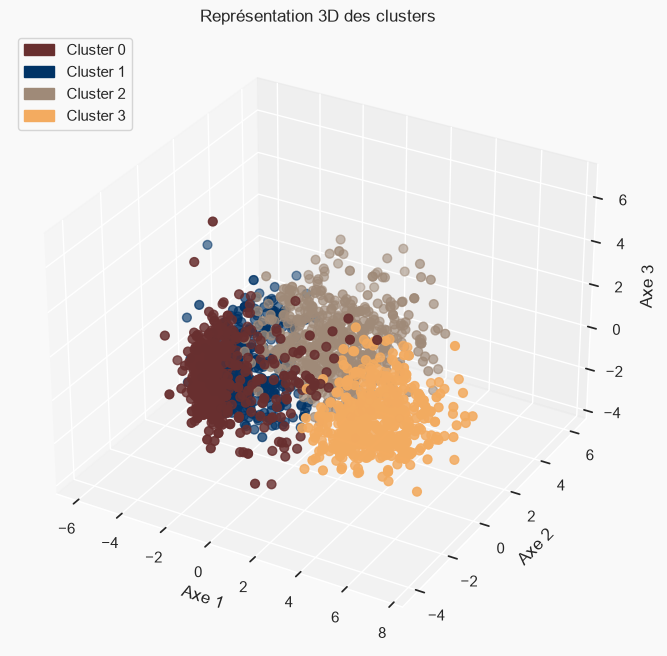

In [30]:
# Visualisation des clusters en 3D
fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(111, projection="3d")
ax.scatter(x, y, z, s=40, c=PCA_ds["Clusters"], marker="o", cmap=cmap, vmin=0, vmax=3)
ax.set_xlabel("Axe 1")
ax.set_ylabel("Axe 2")
ax.set_zlabel("Axe 3")
ax.set_title("Représentation 3D des clusters")
ax.legend(handles=[Patch(color=pal[i], label=f"Cluster {i}") for i in range(4)], loc="upper left")
sauvegarder("02_clusters_3d.png")
plt.show()

La visualisation 3D montre quatre groupes occupant des régions distinctes de l’espace, avec des zones de chevauchement à leurs frontières. La section suivante mesure la qualité de cette segmentation.

***

<a id="7"></a>
# <p style="background-color:#003366;font-family:Georgia;color:#FFF9ED;font-size:150%;text-align:center;border-radius:10px 10px;">📈 ÉVALUATION DE LA SEGMENTATION</p>

En l’absence de variable cible, la qualité de la segmentation s’évalue de deux manières :
* **quantitativement**, avec des indices internes : le **coefficient de silhouette** (entre −1 et 1, plus il est élevé, mieux les groupes sont séparés) et l’**indice de Davies-Bouldin** (plus il est faible, mieux c’est) ;
* **qualitativement**, en vérifiant que les groupes sont de taille exploitable et se distinguent nettement sur des variables métier.


In [31]:
# Indices de qualité de la segmentation retenue
X_pca = PCA_ds.drop(columns="Clusters")
print(f"Coefficient de silhouette (k = 4) : {silhouette_score(X_pca, yhat_AC):.3f}")
print(f"Indice de Davies-Bouldin (k = 4)  : {davies_bouldin_score(X_pca, yhat_AC):.3f}")

# Comparaison avec d'autres nombres de clusters
scores = []
for k in range(2, 9):
    labels_k = AgglomerativeClustering(n_clusters=k, linkage="ward").fit_predict(X_pca)
    scores.append({
        "k": k,
        "Silhouette": silhouette_score(X_pca, labels_k),
        "Davies-Bouldin": davies_bouldin_score(X_pca, labels_k),
    })
pd.DataFrame(scores).set_index("k").round(3)

Coefficient de silhouette (k = 4) : 0.304
Indice de Davies-Bouldin (k = 4)  : 1.188


,Silhouette,Davies-Bouldin
k,,
2,0.390,0.885
3,0.336,1.141
4,0.304,1.188
5,0.276,1.116
6,0.240,1.254
7,0.256,1.284
8,0.266,1.309


Avec un coefficient de silhouette d’environ **0,30** et un indice de Davies-Bouldin d’environ **1,19**, la séparation des groupes est **modérée** : les clusters sont réels mais se recouvrent en partie, ce qui est fréquent sur des données de clientèle où les comportements varient de façon continue.

La silhouette est un peu plus élevée pour k = 2 ou 3. Une segmentation en deux groupes opposerait toutefois simplement les « gros » et les « petits » dépensiers, sans valeur opérationnelle supplémentaire. Le choix de **k = 4** est donc un compromis assumé entre qualité statistique et utilité marketing.

**Observons maintenant la répartition des individus au sein des clusters.**

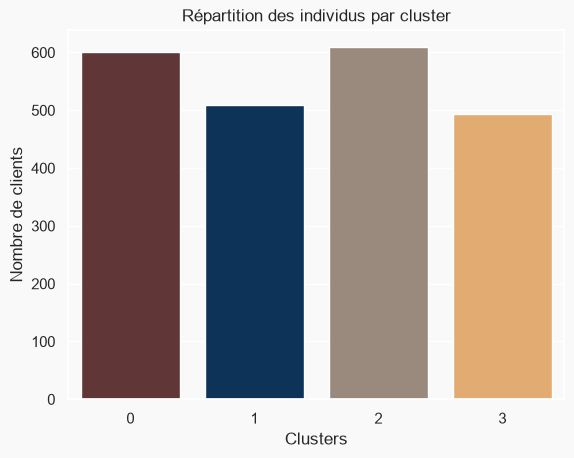

In [32]:
# Répartition des individus dans chaque cluster
pl = sns.countplot(x=data["Clusters"], palette=pal)
pl.set_title("Répartition des individus par cluster")
pl.set_ylabel("Nombre de clients")
sauvegarder("03_repartition_clusters.png")
plt.show()

> Les quatre clusters sont d’effectifs comparables (entre environ 490 et 610 clients) : aucun n’est largement sur- ou sous-représenté. Chaque segment est donc assez important pour justifier une action marketing dédiée.

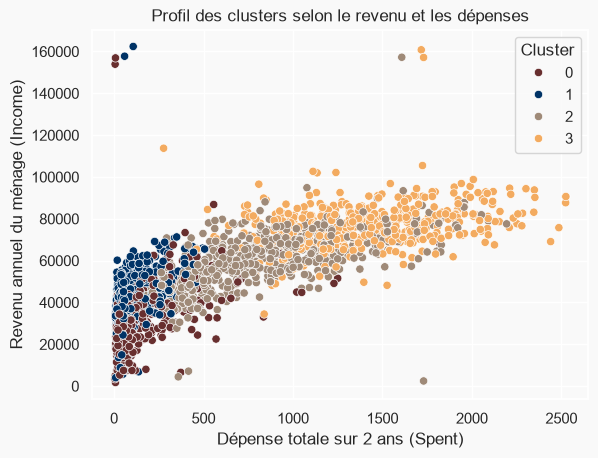

In [33]:
# Profil des clusters selon le revenu et les dépenses
pl = sns.scatterplot(data=data, x="Spent", y="Income", hue="Clusters", palette=pal)
pl.set_title("Profil des clusters selon le revenu et les dépenses")
pl.set_xlabel("Dépense totale sur 2 ans (Spent)")
pl.set_ylabel("Revenu annuel du ménage (Income)")
plt.legend(title="Cluster")
sauvegarder("04_revenu_vs_depenses.png")
plt.show()

**Le nuage de points revenu / dépenses fait apparaître des profils distincts :**
* **Cluster 0 :** revenu le plus faible et dépenses très faibles ;
* **Cluster 1 :** revenu modeste et dépenses faibles ;
* **Cluster 2 :** revenu moyen à élevé et dépenses intermédiaires à élevées ;
* **Cluster 3 :** revenu et dépenses les plus élevés.

Examinons plus en détail la distribution des dépenses dans chaque cluster.


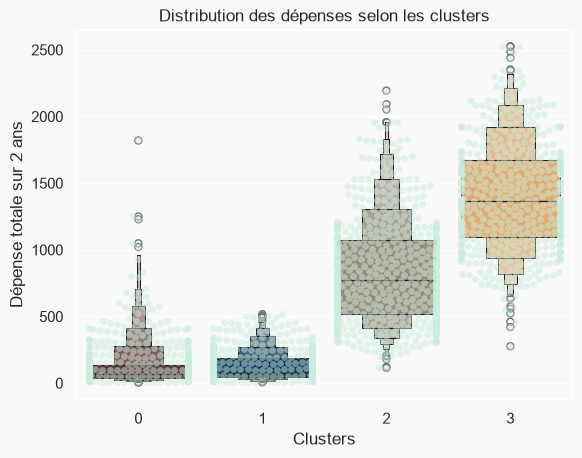

In [34]:
# Distribution des dépenses par cluster
plt.figure()
pl = sns.swarmplot(x=data["Clusters"], y=data["Spent"], color="#CBEDDD", alpha=0.5)
pl = sns.boxenplot(x=data["Clusters"], y=data["Spent"], palette=pal)
pl.set_title("Distribution des dépenses selon les clusters")
pl.set_ylabel("Dépense totale sur 2 ans")
sauvegarder("05_distribution_depenses.png")
plt.show()

Le graphique illustre la distribution des dépenses totales (`Spent`) dans chaque cluster :

- les clusters 2 et 3 dépensent nettement plus que les clusters 0 et 1 ;
- le cluster 3 regroupe les clients aux dépenses les plus élevées, suivi du cluster 2 ;
- les clusters 0 et 1 sont composés de clients aux dépenses globalement faibles.

Les comportements de consommation diffèrent donc fortement d’un segment à l’autre.


Qu’en est-il des performances des campagnes marketing passées ?

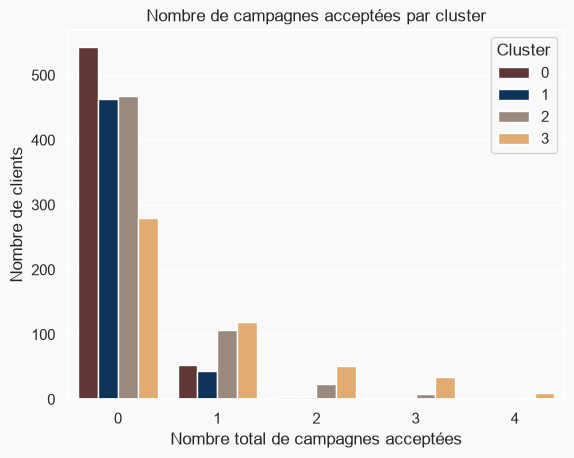

Part des clients n'ayant accepté aucune campagne : 79.3%


,Total_Promos,Response
Clusters,,
0,0.10,0.12
1,0.10,0.06
2,0.31,0.12
3,0.73,0.31


In [35]:
# Nombre total de campagnes acceptées par client
data["Total_Promos"] = (
    data["AcceptedCmp1"] + data["AcceptedCmp2"] + data["AcceptedCmp3"] + data["AcceptedCmp4"] + data["AcceptedCmp5"]
)

plt.figure()
pl = sns.countplot(x=data["Total_Promos"], hue=data["Clusters"], palette=pal)
pl.set_title("Nombre de campagnes acceptées par cluster")
pl.set_xlabel("Nombre total de campagnes acceptées")
pl.set_ylabel("Nombre de clients")
plt.legend(title="Cluster")
sauvegarder("06_promos_par_cluster.png")
plt.show()

print(f"Part des clients n'ayant accepté aucune campagne : {(data['Total_Promos'] == 0).mean():.1%}")
data.groupby("Clusters")[["Total_Promos", "Response"]].mean().round(2)

> Près de **8 clients sur 10** n’ont accepté aucune des cinq campagnes, et aucun client ne les a toutes acceptées : les campagnes passées ont eu une portée limitée.
>
> Le **cluster 3** se distingue nettement : c’est le segment qui accepte le plus de campagnes (0,7 en moyenne contre 0,1 à 0,3 pour les autres) et qui a le mieux répondu à la dernière (environ 31 %). Des campagnes mieux ciblées permettraient de concentrer les efforts là où ils portent leurs fruits.


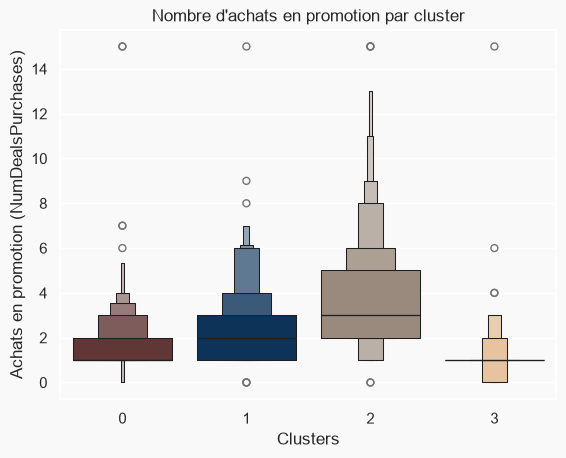

In [36]:
# Nombre d'achats effectués en promotion par cluster
plt.figure()
pl = sns.boxenplot(y=data["NumDealsPurchases"], x=data["Clusters"], palette=pal)
pl.set_title("Nombre d'achats en promotion par cluster")
pl.set_ylabel("Achats en promotion (NumDealsPurchases)")
sauvegarder("07_deals_par_cluster.png")
plt.show()

> Les clients du **cluster 2** sont ceux qui effectuent le plus d’achats en promotion (médiane de 3, avec des valeurs pouvant dépasser 10). Les clusters 0 et 1 en réalisent moins, et le **cluster 3**, le plus dépensier, en achète très peu (médiane de 1).

**Remises et campagnes ne touchent donc pas les mêmes clients.** Le cluster 2 est sensible aux **prix promotionnels**, tandis que le cluster 3 répond aux **campagnes** mais n’a pas besoin de remises pour acheter. Une politique promotionnelle uniforme est donc inadaptée : il faut deux leviers distincts.


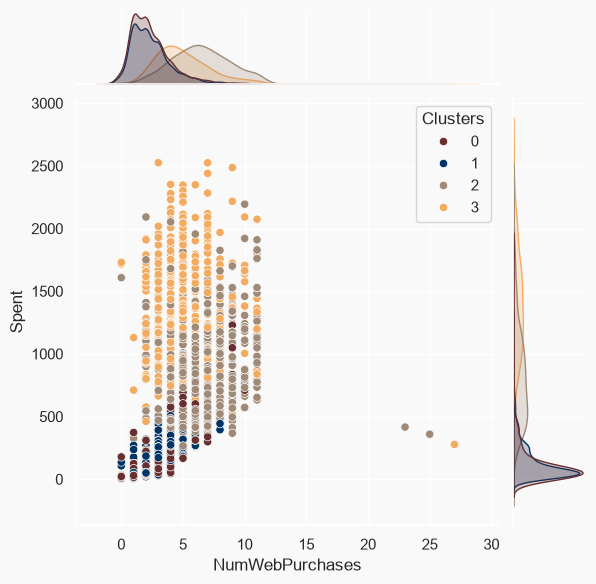

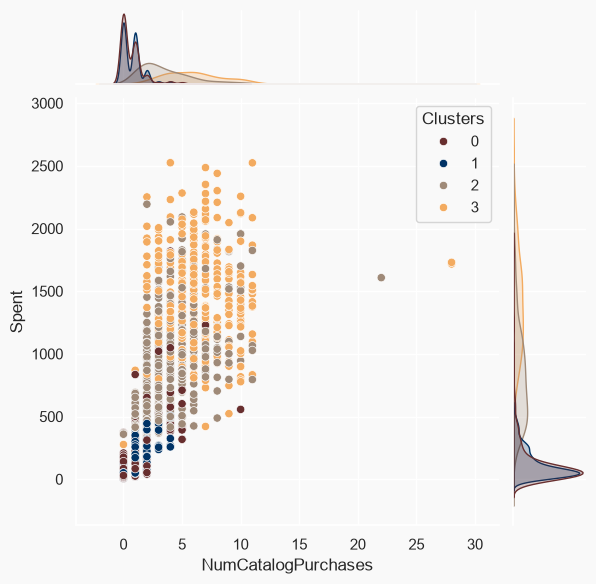

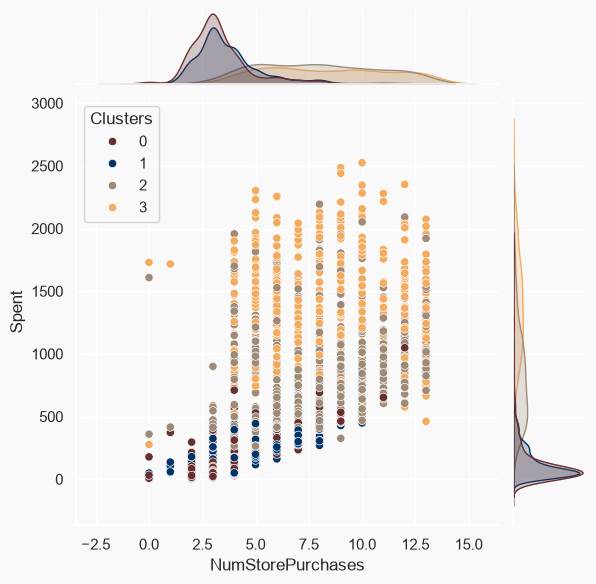

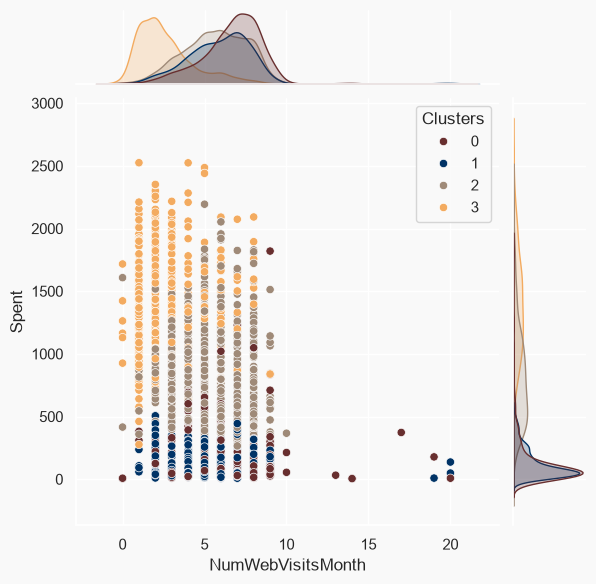

,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth
Clusters,,,,
0,2.3,0.7,3.4,6.7
1,2.3,0.7,3.6,5.9
2,6.5,3.6,7.9,5.6
3,5.0,6.0,8.3,2.6


In [37]:
# Canaux d'achat et dépenses selon les clusters
lieux_achat = ["NumWebPurchases", "NumCatalogPurchases", "NumStorePurchases", "NumWebVisitsMonth"]

for var in lieux_achat:
    sns.jointplot(x=data[var], y=data["Spent"], hue=data["Clusters"], palette=pal)
    plt.show()

data.groupby("Clusters")[lieux_achat].mean().round(1)

L’analyse croisée des canaux d’achat et des dépenses fait ressortir des usages différents :

* le **cluster 3** achète surtout **par catalogue et en magasin**, et visite peu le site web ;
* le **cluster 2** est le plus actif **sur le web** et achète aussi beaucoup en magasin ;
* les **clusters 0 et 1** visitent souvent le site mais y achètent peu : le trafic web de ces segments se convertit mal.

>Ces résultats appellent un **profilage** plus approfondi afin de caractériser chaque segment et d’identifier les leviers commerciaux les plus pertinents.


<a id="8"></a>
# <p style="background-color:#003366;font-family:Georgia;color:#FFF9ED;font-size:150%;text-align:center;border-radius:10px 10px;">👥 PROFILAGE DES CLUSTERS</p>

Après avoir constitué les clusters et analysé leurs habitudes d’achat, intéressons-nous à leur composition. Ce **profilage** vise à identifier les clients les plus précieux et les segments qui demandent une attention particulière de l’équipe marketing.

Commençons par un tableau récapitulatif des moyennes par cluster.


In [38]:
# Tableau de synthèse des profils (moyennes par cluster)
profil = data.groupby("Clusters").agg(
    Effectif=("Income", "size"),
    Revenu=("Income", "mean"),
    Depense_totale=("Spent", "mean"),
    Age=("Age", "mean"),
    Part_parents=("Is_Parent", "mean"),
    Enfants=("Kidhome", "mean"),
    Adolescents=("Teenhome", "mean"),
    Taille_foyer=("Family_Size", "mean"),
    Taille_foyer_max=("Family_Size", "max"),
    Achats_promo=("NumDealsPurchases", "mean"),
    Campagnes_acceptees=("Total_Promos", "mean"),
    Reponse_derniere_campagne=("Response", "mean"),
)
profil.round(2).T

Clusters,0,1,2,3
Effectif,600.00,509.00,609.00,494.00
Revenu,31163.83,42641.73,60135.16,76736.10
Depense_totale,129.69,127.17,832.78,1403.98
Age,37.46,49.26,48.21,46.20
Part_parents,0.73,1.00,1.00,0.05
Enfants,0.72,0.78,0.24,0.01
Adolescents,0.01,1.02,0.94,0.05
Taille_foyer,2.35,3.48,2.89,1.62
Taille_foyer_max,3.00,5.00,5.00,2.00
Achats_promo,1.76,2.54,3.70,1.09


**Pour affiner ces profils, examinons la relation entre les caractéristiques personnelles des clients et leurs dépenses totales, selon leur cluster.**

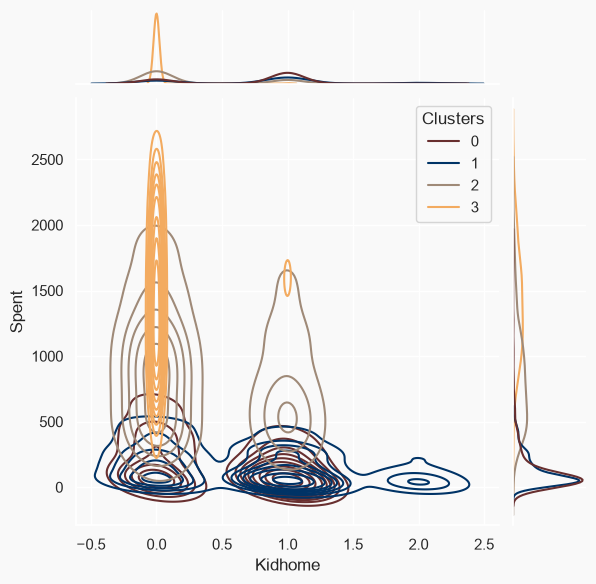

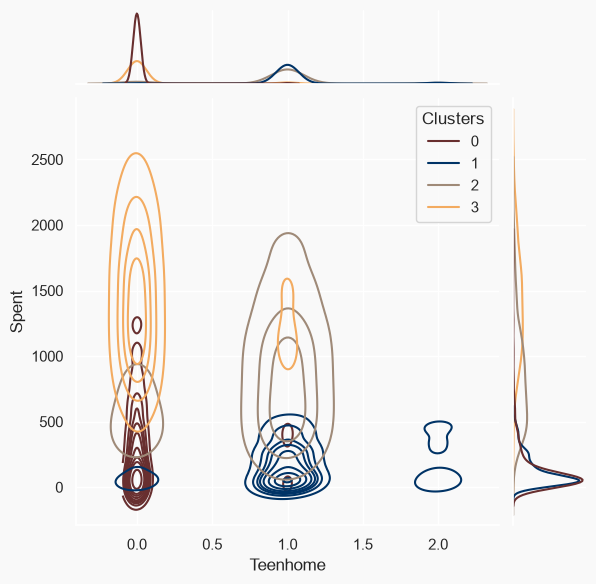

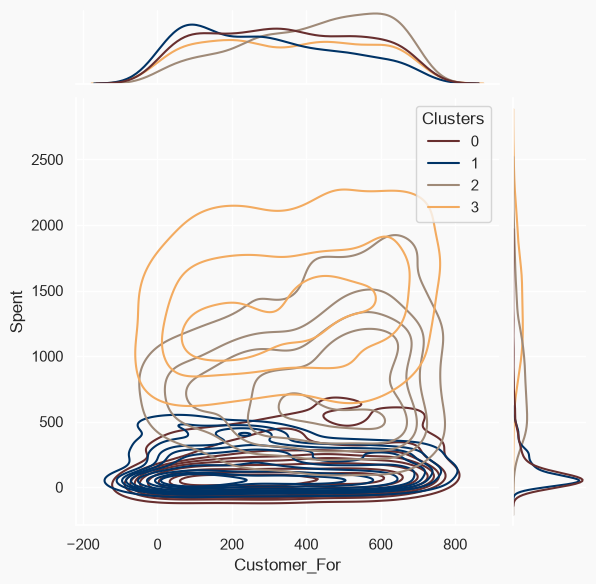

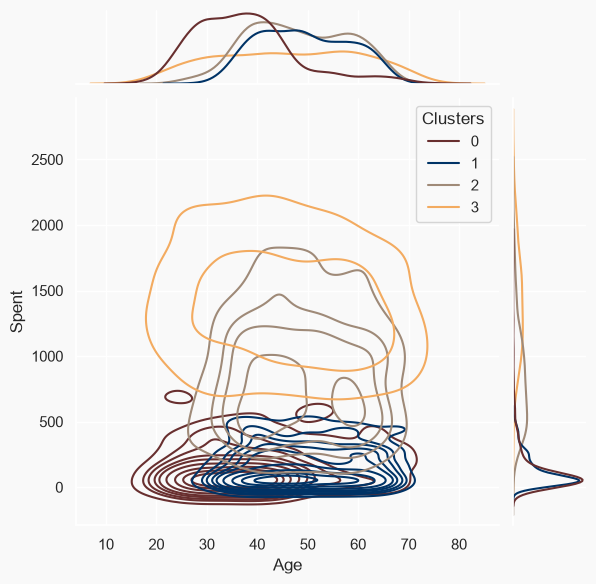

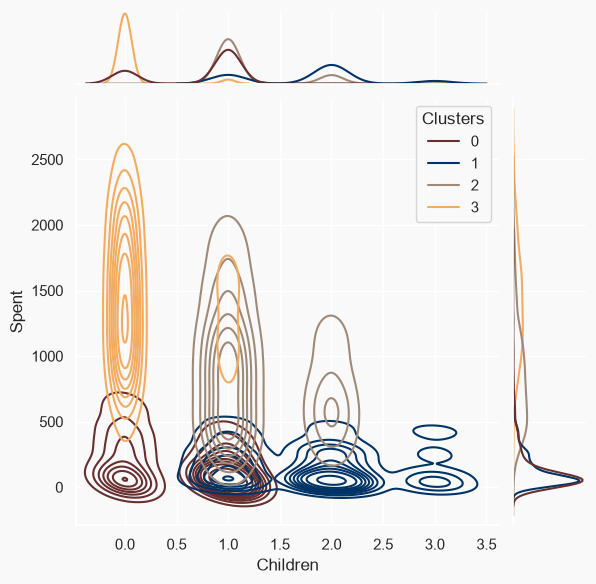

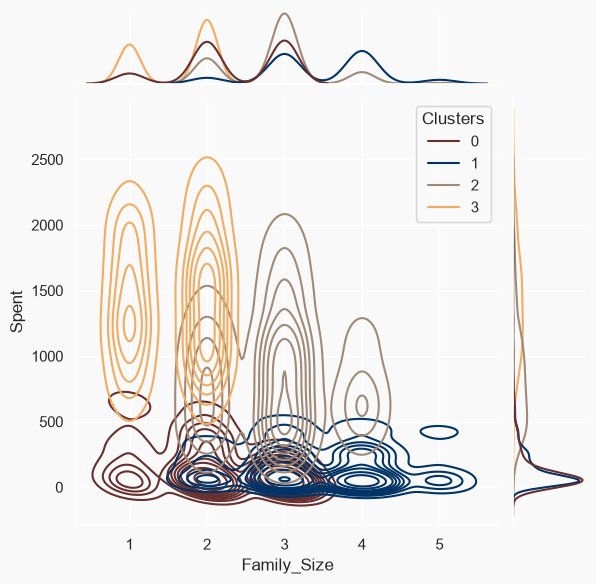

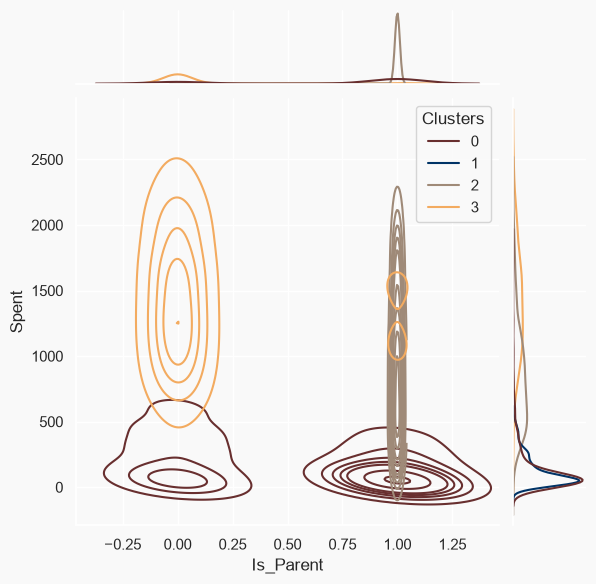

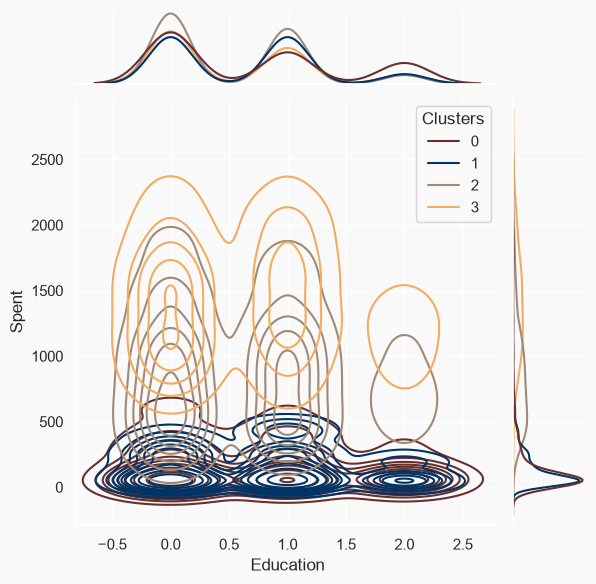

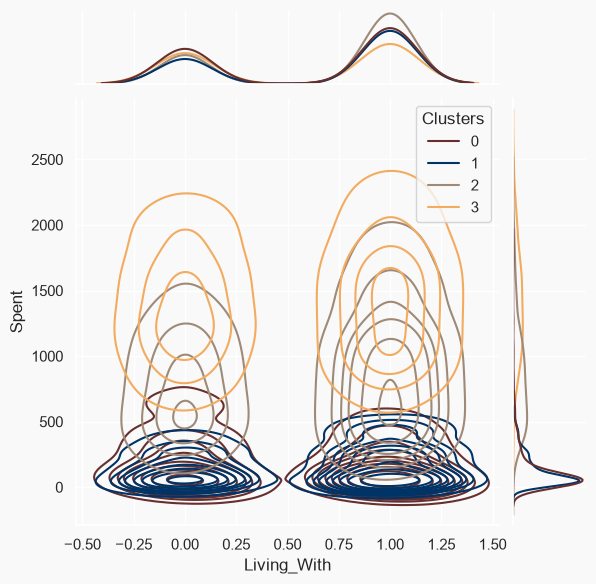

In [39]:
# Profil personnel des clients selon leur cluster
variables_personnelles = ["Kidhome", "Teenhome", "Customer_For", "Age", "Children", "Family_Size", "Is_Parent", "Education", "Living_With"]

for var in variables_personnelles:
    sns.jointplot(x=data[var], y=data["Spent"], hue=data["Clusters"], kind="kde", palette=pal)
    plt.show()

**PROFILAGE DES CLIENTS**

| Cluster | Profil | Description synthétique |
| :-----: | :----- | :---------------------- |
| **Cluster 0** | Jeunes foyers modestes | • Les **plus jeunes** (37 ans en moyenne).<br>• **Revenu le plus faible** et **dépenses très faibles**.<br>• Environ 3 sur 4 sont **parents**, presque toujours d’**enfants en bas âge** (pas d’adolescent).<br>• Foyers de **1 à 3 personnes**.<br>• Visitent souvent le site web mais achètent peu. |
| **Cluster 1** | Familles nombreuses à budget serré | • **Tous parents**, souvent avec **un adolescent et un jeune enfant**.<br>• Foyers de **2 à 5 personnes**, les plus grands en moyenne.<br>• Les **plus âgés** (49 ans en moyenne).<br>• **Revenu modeste** et **dépenses faibles**.<br>• Réponse la plus faible à la dernière campagne. |
| **Cluster 2** | Familles aisées sensibles aux promotions | • **Tous parents**, le plus souvent d’**adolescents**.<br>• Foyers de **2 à 5 personnes**.<br>• Environ 48 ans en moyenne.<br>• **Revenu et dépenses intermédiaires à élevés**.<br>• **Record d’achats en promotion** ; très actifs sur le web. |
| **Cluster 3** | Clients premium sans enfant | • **Quasiment aucun enfant** (95 % de non-parents).<br>• Foyers de **1 à 2 personnes**, en couple ou seuls.<br>• Environ 46 ans en moyenne.<br>• **Revenu et dépenses les plus élevés**.<br>• Achètent **peu en promotion** mais **acceptent le plus de campagnes** ; achats surtout par catalogue et en magasin. |


<a id="9"></a>
# <p style="background-color:#003366;font-family:Georgia;color:#FFF9ED;font-size:150%;text-align:center;border-radius:10px 10px;">🧾 CONCLUSION</p>

Ce projet visait à identifier des groupes homogènes de clients à partir de leurs caractéristiques sociodémographiques et comportementales, afin d’orienter des actions marketing ciblées.

Une approche de **clustering non supervisé** a été mise en œuvre, précédée d’une **réduction de dimension** par ACP. Le **clustering agglomératif** a permis d’extraire **quatre segments** d’effectifs comparables, qui se distinguent nettement par la structure familiale, le revenu, les dépenses et la réaction aux actions commerciales.

**Principaux enseignements :**
* le revenu et la présence d’enfants sont les deux facteurs qui structurent le plus la clientèle ;
* **les remises et les campagnes ne touchent pas les mêmes clients** : le cluster 2 (familles aisées) est le plus sensible aux prix promotionnels, tandis que le cluster 3 (clients premium sans enfant) achète peu en promotion mais répond le mieux aux campagnes ;
* les clusters 0 et 1, à faible pouvoir d’achat, visitent le site sans beaucoup acheter : ils représentent un potentiel de conversion.

**Limites de l’étude :**
* la séparation des clusters est modérée (silhouette ≈ 0,30) ;
* le nombre de clusters a été choisi avec l’inertie de KMeans alors que l’algorithme final est agglomératif ; un dendrogramme serait plus cohérent ;
* plusieurs variables familiales redondantes (`Kidhome`, `Teenhome`, `Children`, `Family_Size`, `Is_Parent`), ainsi que `Spent` et ses composantes, pèsent davantage dans l’ACP ;
* `Education` est encodée par ordre alphabétique plutôt que par niveau d’études ;
* les 24 clients sans revenu ont été supprimés plutôt qu’imputés.

Cette étude illustre l’intérêt des techniques de data mining pour la segmentation de la clientèle, en fournissant aux décideurs des informations directement exploitables pour cibler les campagnes commerciales.


<a id="10"></a>
# <p style="background-color:#003366;font-family:Georgia;color:#FFF9ED;font-size:150%;text-align:center;border-radius:10px 10px;">📚 SOURCES</p>

* **Données :** *Customer Personality Analysis*, jeu de données public publié sur Kaggle par Akash Patel — https://www.kaggle.com/datasets/imakash3011/customer-personality-analysis
* **Démarche :** la préparation des données et l’enchaînement ACP + clustering agglomératif s’inspirent du notebook Kaggle *Customer Segmentation: Clustering* de Karnika Kapoor — https://www.kaggle.com/code/karnikakapoor/customer-segmentation-clustering . L’évaluation, l’interprétation des résultats et le profilage des clusters ont été réalisés par l’équipe.
